In [6]:
pip install pandas

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [12]:
pip install seaborn


Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 294 kB 951 kB/s eta 0:00:01
     |████████████████████████████████| 7.9 MB 2.6 MB/s eta 0:00:01
     |████████████████████████████████| 126 kB 4.0 MB/s eta 0:00:01
     |████████████████████████████████| 5.3 MB 2.6 MB/s eta 0:00:01
     |████████████████████████████████| 265 kB 3.0 MB/s eta 0:00:01
     |████████████████████████████████| 65 kB 2.5 MB/s eta 0:00:01
     |████████████████████████████████| 2.4 MB 2.3 MB/s eta 0:00:01
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [27]:
pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 12.1 MB 484 kB/s eta 0:00:01
     |████████████████████████████████| 309 kB 1.2 MB/s eta 0:00:01
     |████████████████████████████████| 39.4 MB 21 kB/s  eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [7]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
sns.set()

# Chargement des données
#df = pd.read_csv('http://www.oasis-brains.org/pdf/oasis_longitudinal.csv')
df = pd.read_csv('oasis_longitudinal.csv')
# print("Premiers enregistrements:\n", df.head())

# Affichage du dataset
from IPython.display import display
pd.options.display.max_columns = None 
print("Dataset:\n")
display(df)

Dataset:



,Subject ID,MRI ID,Group,Visit,MR Delay,M/F,Hand,Age,EDUC,SES,MMSE,CDR,eTIV,nWBV,ASF
0,OAS2_0001,OAS2_0001_MR1,Nondemented,1,0,M,R,87,14,2.0,27.0,0.0,1987,0.696,0.883
1,OAS2_0001,OAS2_0001_MR2,Nondemented,2,457,M,R,88,14,2.0,30.0,0.0,2004,0.681,0.876
2,OAS2_0002,OAS2_0002_MR1,Demented,1,0,M,R,75,12,NaN,23.0,0.5,1678,0.736,1.046
3,OAS2_0002,OAS2_0002_MR2,Demented,2,560,M,R,76,12,NaN,28.0,0.5,1738,0.713,1.010
4,OAS2_0002,OAS2_0002_MR3,Demented,3,1895,M,R,80,12,NaN,22.0,0.5,1698,0.701,1.034
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
368,OAS2_0185,OAS2_0185_MR2,Demented,2,842,M,R,82,16,1.0,28.0,0.5,1693,0.694,1.037
369,OAS2_0185,OAS2_0185_MR3,Demented,3,2297,M,R,86,16,1.0,26.0,0.5,1688,0.675,1.040
370,OAS2_0186,OAS2_0186_MR1,Nondemented,1,0,F,R,61,13,2.0,30.0,0.0,1319,0.801,1.331
371,OAS2_0186,OAS2_0186_MR2,Nondemented,2,763,F,R,63,13,2.0,30.0,0.0,1327,0.796,1.323


In [8]:
print("Dataset Shape:", df.shape) 
df.info()

Dataset Shape: (373, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 373 entries, 0 to 372
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Subject ID  373 non-null    object 
 1   MRI ID      373 non-null    object 
 2   Group       373 non-null    object 
 3   Visit       373 non-null    int64  
 4   MR Delay    373 non-null    int64  
 5   M/F         373 non-null    object 
 6   Hand        373 non-null    object 
 7   Age         373 non-null    int64  
 8   EDUC        373 non-null    int64  
 9   SES         354 non-null    float64
 10  MMSE        371 non-null    float64
 11  CDR         373 non-null    float64
 12  eTIV        373 non-null    int64  
 13  nWBV        373 non-null    float64
 14  ASF         373 non-null    float64
dtypes: float64(5), int64(5), object(5)
memory usage: 43.8+ KB


In [9]:
df.describe()

,Visit,MR Delay,Age,EDUC,SES,MMSE,CDR,eTIV,nWBV,ASF
count,373.000000,373.000000,373.000000,373.000000,354.000000,371.000000,373.000000,373.000000,373.000000,373.000000
mean,1.882038,595.104558,77.013405,14.597855,2.460452,27.342318,0.290885,1488.128686,0.729568,1.195461
std,0.922843,635.485118,7.640957,2.876339,1.134005,3.683244,0.374557,176.139286,0.037135,0.138092
min,1.000000,0.000000,60.000000,6.000000,1.000000,4.000000,0.000000,1106.000000,0.644000,0.876000
25%,1.000000,0.000000,71.000000,12.000000,2.000000,27.000000,0.000000,1357.000000,0.700000,1.099000
50%,2.000000,552.000000,77.000000,15.000000,2.000000,29.000000,0.000000,1470.000000,0.729000,1.194000
75%,2.000000,873.000000,82.000000,16.000000,3.000000,30.000000,0.500000,1597.000000,0.756000,1.293000
max,5.000000,2639.000000,98.000000,23.000000,5.000000,30.000000,2.000000,2004.000000,0.837000,1.587000


In [10]:
# Activer l'option pour éviter le warning de Pandas
pd.set_option('future.no_silent_downcasting', True)

# Nettoyage du dataset (adapté aux colonnes présentes)
# Note : Pas de filtre sur 'Visit' car la colonne n'existe pas dans le fichier

# Remplacement des valeurs textuelles par des chiffres
df['M/F'] = df['M/F'].replace(['F', 'M'], [0, 1]) # M/F column (0 pour F, 1 pour M)
df['Group'] = df['Group'].replace(['Converted'], ['Demented'])  
df['Group'] = df['Group'].replace(['Demented', 'Nondemented'], [1, 0]) # Target (1 pour Demented, 0 pour Nondemented)

# Suppression uniquement des colonnes inutiles présentes dans votre fichier (ex: 'Subject ID')
df = df.drop(['Subject ID'], axis=1) 

print("Nettoyage terminé avec succès ! Aperçu :")
display(df.head())

Nettoyage terminé avec succès ! Aperçu :


,MRI ID,Group,Visit,MR Delay,M/F,Hand,Age,EDUC,SES,MMSE,CDR,eTIV,nWBV,ASF
0,OAS2_0001_MR1,0,1,0,1,R,87,14,2.0,27.0,0.0,1987,0.696,0.883
1,OAS2_0001_MR2,0,2,457,1,R,88,14,2.0,30.0,0.0,2004,0.681,0.876
2,OAS2_0002_MR1,1,1,0,1,R,75,12,NaN,23.0,0.5,1678,0.736,1.046
3,OAS2_0002_MR2,1,2,560,1,R,76,12,NaN,28.0,0.5,1738,0.713,1.010
4,OAS2_0002_MR3,1,3,1895,1,R,80,12,NaN,22.0,0.5,1698,0.701,1.034


In [11]:
df.describe()

,Group,MR Delay,M/F,Age,EDUC,SES,MMSE,CDR,eTIV,nWBV,ASF
count,150.000000,150.0,150.000000,150.000000,150.000000,142.000000,150.00000,150.000000,150.000000,150.000000,150.000000
mean,0.520000,0.0,0.413333,75.446667,14.533333,2.492958,27.56000,0.260000,1474.426667,0.736073,1.206333
std,0.501274,0.0,0.494081,7.545421,2.874714,1.128273,2.96847,0.326256,174.683889,0.036458,0.137864
min,0.000000,0.0,0.000000,60.000000,6.000000,1.000000,17.00000,0.000000,1123.000000,0.660000,0.883000
25%,0.000000,0.0,0.000000,70.000000,12.000000,2.000000,26.00000,0.000000,1347.250000,0.710000,1.121000
50%,1.000000,0.0,0.000000,75.000000,14.000000,2.000000,29.00000,0.000000,1453.500000,0.735000,1.207500
75%,1.000000,0.0,1.000000,80.000000,16.000000,3.000000,30.00000,0.500000,1565.250000,0.757750,1.302750
max,1.000000,0.0,1.000000,96.000000,23.000000,5.000000,30.00000,1.000000,1987.000000,0.837000,1.563000


Text(0.5, 1.0, 'Gender and Demented rate')

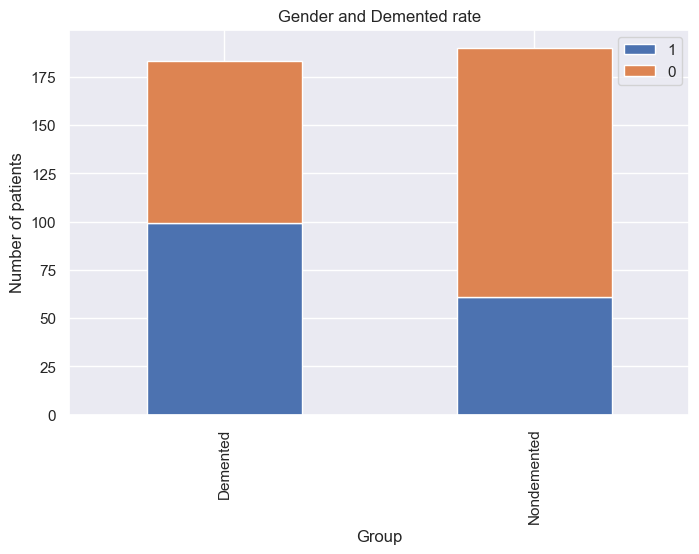

In [11]:
## GRAPH 1 - Dementia per genre
# bar drawing function
def bar_chart(feature):
    Demented = df[df['Group']==1][feature].value_counts() 
    Nondemented = df[df['Group']==0][feature].value_counts() 
    df_bar = pd.DataFrame([Demented,Nondemented]) 
    df_bar.index = ['Demented','Nondemented']
    df_bar.plot(kind='bar',stacked=True, figsize=(8,5))
# Gender and Group ( Femal=0, Male=1)
bar_chart('M/F') 
plt.xlabel('Group') 
plt.ylabel('Number of patients') 
plt.legend()
plt.title('Gender and Demented rate')

(15.3, 30.0)

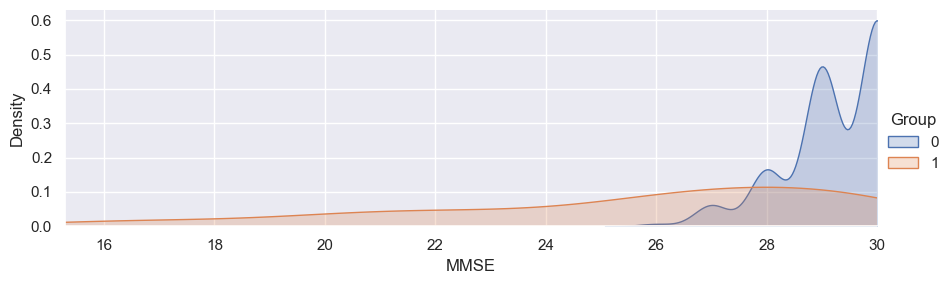

In [12]:
## GRAPH 2 - MMSE per dementia
#MMSE : Mini Mental State Examination
# Nondemented = 0, Demented =1
# Nondemented has higher test result ranging from 25 to 30. #Min 17 ,MAX 30
facet= sns.FacetGrid(df,hue="Group", aspect=3)
facet.map(sns.kdeplot,'MMSE',fill= True)
facet.set(xlim=(0, df['MMSE'].max()))
facet.add_legend()
plt.xlim(15.30)

(0.6, 0.9)

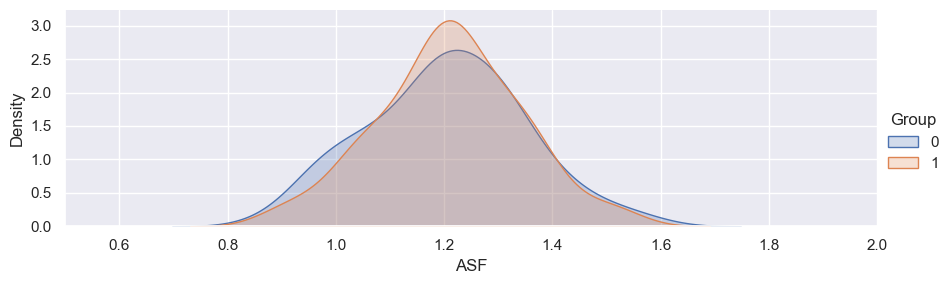

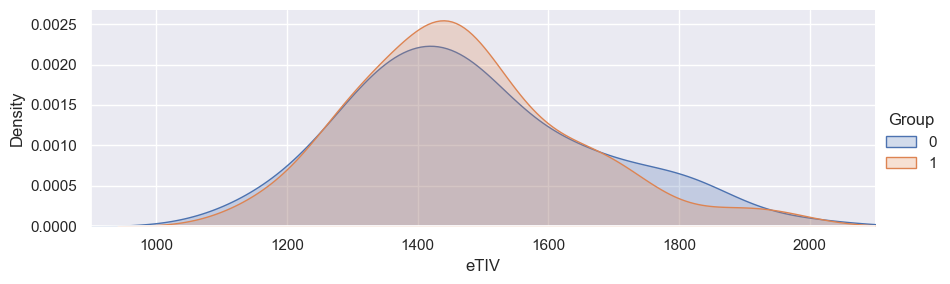

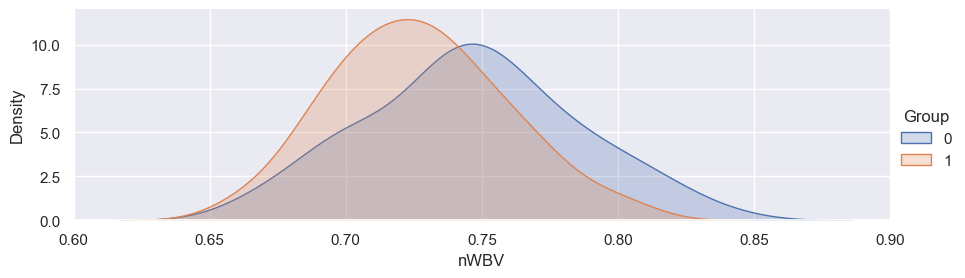

In [18]:
## GRAPH 3 - ASF, eTIV, nWBV per dementia
#bar_chart('ASF') = Atlas Scaling Factor
facet= sns.FacetGrid(df,hue="Group", aspect=3) 
facet.map(sns.kdeplot,'ASF',fill= True) 
facet.set(xlim=(0, df['ASF'].max())) 
facet.add_legend()
plt.xlim(0.5, 2)

#eTIV = Estimated Total Intracranial Volume
facet= sns.FacetGrid(df,hue="Group", aspect=3) 
facet.map(sns.kdeplot,'eTIV',fill= True) 
facet.set(xlim=(0, df['eTIV'].max())) 
facet.add_legend()
plt.xlim(900, 2100)

#'nWBV' = Normalized Whole Brain Volume
# Nondemented = 0, Demented =1
facet= sns.FacetGrid(df,hue="Group", aspect=3) 
facet.map(sns.kdeplot,'nWBV',fill= True) 
facet.set(xlim=(0, df['nWBV'].max())) 
facet.add_legend()
plt.xlim(0.6,0.9)

(0.0, 0.16)

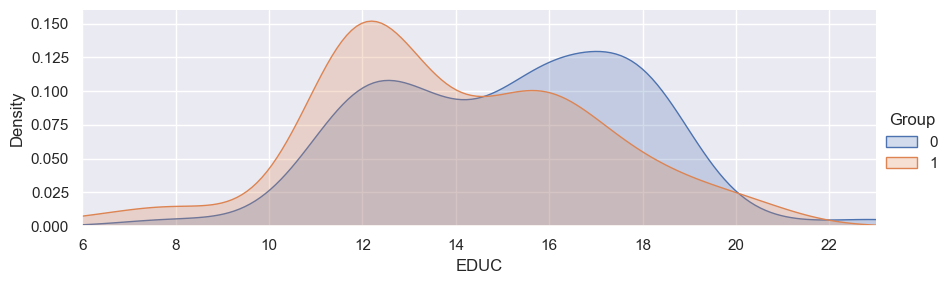

In [20]:
## GRAPH 5 - Education per dementia
#'EDUC' = Years of Education
# Nondemented = 0, Demented =1
facet= sns.FacetGrid(df,hue="Group", aspect=3) 
facet.map(sns.kdeplot,'EDUC',fill= True) 
facet.set(xlim=(df['EDUC'].min(), df['EDUC'].max())) 
facet.add_legend()
plt.ylim(0, 0.16)

In [21]:
df.describe()

,Group,MR Delay,M/F,Age,EDUC,SES,MMSE,CDR,eTIV,nWBV,ASF
count,150.000000,150.0,150.000000,150.000000,150.000000,142.000000,150.00000,150.000000,150.000000,150.000000,150.000000
mean,0.520000,0.0,0.413333,75.446667,14.533333,2.492958,27.56000,0.260000,1474.426667,0.736073,1.206333
std,0.501274,0.0,0.494081,7.545421,2.874714,1.128273,2.96847,0.326256,174.683889,0.036458,0.137864
min,0.000000,0.0,0.000000,60.000000,6.000000,1.000000,17.00000,0.000000,1123.000000,0.660000,0.883000
25%,0.000000,0.0,0.000000,70.000000,12.000000,2.000000,26.00000,0.000000,1347.250000,0.710000,1.121000
50%,1.000000,0.0,0.000000,75.000000,14.000000,2.000000,29.00000,0.000000,1453.500000,0.735000,1.207500
75%,1.000000,0.0,1.000000,80.000000,16.000000,3.000000,30.00000,0.500000,1565.250000,0.757750,1.302750
max,1.000000,0.0,1.000000,96.000000,23.000000,5.000000,30.00000,1.000000,1987.000000,0.837000,1.563000


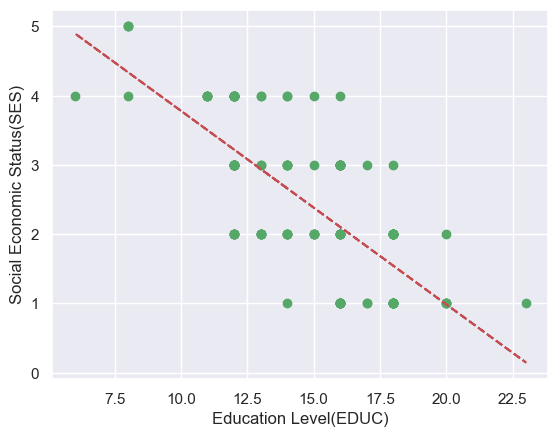

SES
False    150
Name: count, dtype: int64

In [23]:
# Check missing values by each column
pd.isnull(df).sum() 
# The column, SES has 8 missing values

# Dropped the 8 rows with missing values in the column, SES
df_dropna = df.dropna(axis=0, how='any')
pd.isnull(df_dropna).sum()

df_dropna['Group'].value_counts()

# Draw scatter plot between EDUC and SES
x = df['EDUC']
y = df['SES']

ses_not_null_index = y[~y.isnull()].index
x = x[ses_not_null_index]
y = y[ses_not_null_index]

# Draw trend line in red
z = np.polyfit(x, y, 1)
p = np.poly1d(z)
plt.plot(x, y, 'go', x, p(x), "r--")
plt.xlabel('Education Level(EDUC)')
plt.ylabel('Social Economic Status(SES)')

plt.show()

df.groupby(['EDUC'])['SES'].median()

# Remplacement sans inplace=True pour éviter le warning
df["SES"] = df["SES"].fillna(df.groupby("EDUC")["SES"].transform("median"))


# I confirm there're no more missing values and all the 150 data were used.
pd.isnull(df['SES']).value_counts()

In [24]:
df.describe()

,Group,MR Delay,M/F,Age,EDUC,SES,MMSE,CDR,eTIV,nWBV,ASF
count,150.000000,150.0,150.000000,150.000000,150.000000,150.000000,150.00000,150.000000,150.000000,150.000000,150.000000
mean,0.520000,0.0,0.413333,75.446667,14.533333,2.513333,27.56000,0.260000,1474.426667,0.736073,1.206333
std,0.501274,0.0,0.494081,7.545421,2.874714,1.103604,2.96847,0.326256,174.683889,0.036458,0.137864
min,0.000000,0.0,0.000000,60.000000,6.000000,1.000000,17.00000,0.000000,1123.000000,0.660000,0.883000
25%,0.000000,0.0,0.000000,70.000000,12.000000,2.000000,26.00000,0.000000,1347.250000,0.710000,1.121000
50%,1.000000,0.0,0.000000,75.000000,14.000000,2.000000,29.00000,0.000000,1453.500000,0.735000,1.207500
75%,1.000000,0.0,1.000000,80.000000,16.000000,3.000000,30.00000,0.500000,1565.250000,0.757750,1.302750
max,1.000000,0.0,1.000000,96.000000,23.000000,5.000000,30.00000,1.000000,1987.000000,0.837000,1.563000


In [14]:
# Créez df_dropna 
df_dropna = df.dropna(axis=0, how='any')

In [16]:
## Splitting Train/Validation/Test Sets

from sklearn.model_selection import train_test_split
from sklearn import preprocessing
from sklearn.preprocessing import MinMaxScaler 
from sklearn.model_selection import cross_val_score

# Dataset with imputation
Y = df['Group'].values # Target for the model
X = df[['M/F', 'Age', 'EDUC', 'SES', 'MMSE', 'eTIV', 'nWBV', 'ASF']] # Features we use

# splitting into three sets
X_trainval, X_test, Y_trainval, Y_test = train_test_split(X, Y, random_state=0)

# Feature scaling
scaler = MinMaxScaler().fit(X_trainval)
X_trainval_scaled = scaler.transform(X_trainval)
X_test_scaled = scaler.transform(X_test)

# Dataset after dropping missing value rows
Y = df_dropna['Group'].values # Target for the model
X = df_dropna[['M/F', 'Age', 'EDUC', 'SES', 'MMSE', 'eTIV', 'nWBV', 'ASF']] # Features we use

# splitting into three sets
X_trainval_dna, X_test_dna, Y_trainval_dna, Y_test_dna = train_test_split(X, Y, random_state=0)

# Feature scaling
scaler = MinMaxScaler().fit(X_trainval_dna)
X_trainval_scaled_dna = scaler.transform(X_trainval_dna)
X_test_scaled_dna = scaler.transform(X_test_dna)

In [17]:
# Regression logistique
# No convergence warnings
import warnings
from sklearn.exceptions import ConvergenceWarning 
warnings.filterwarnings(action='ignore', category=ConvergenceWarning)

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, roc_curve, auc

import time
tps_tot = time.perf_counter()

acc = [] # list to store all performance metric

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, roc_curve, auc

import time
tps_tot = time.perf_counter()

acc = [] # list to store all performance metric

In [ ]:
Model logistic regression (avec imputation)

In [22]:
import time
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score, roc_curve, auc
from sklearn.exceptions import ConvergenceWarning
import warnings

# Ignorer les avertissements de convergence
warnings.filterwarnings(action='ignore', category=ConvergenceWarning)

# 1. Nettoyage de sécurité pour s'assurer que Group est bien encodé (0 et 1)
df['Group'] = df['Group'].replace(['Converted'], ['Demented'])  
df['Group'] = df['Group'].replace(['Demented', 'Nondemented'], [1, 0])

# 2. Imputation des valeurs manquantes
df["SES"] = df["SES"].fillna(df.groupby("EDUC")["SES"].transform("median"))
df = df.fillna(df.median(numeric_only=True))

# 3. Préparation des données (et conversion explicite de Y en entiers)
Y = df['Group'].values.astype(int) 
X = df[['M/F', 'Age', 'EDUC', 'SES', 'MMSE', 'eTIV', 'nWBV', 'ASF']]

# 4. Séparation Train / Test
X_trainval, X_test, Y_trainval, Y_test = train_test_split(X, Y, random_state=0)

# 5. Normalisation (Feature Scaling)
scaler = MinMaxScaler().fit(X_trainval)
X_trainval_scaled = scaler.transform(X_trainval)
X_test_scaled = scaler.transform(X_test)

# 6. Recherche du meilleur paramètre C avec validation croisée
tps = time.perf_counter()
best_score = 0
best_parameters = None
kfolds = 5

for c in [0.001, 0.1, 1, 10, 100]:
    logRegModel = LogisticRegression(C=c)
    
    scores = cross_val_score(logRegModel, X_trainval_scaled, Y_trainval, cv=kfolds, scoring='accuracy')
    score = np.mean(scores)
    
    if score > best_score:
        best_score = score
        best_parameters = c

# 7. Réentraînement du modèle final et calcul des métriques
SelectedLogRegModel = LogisticRegression(C=best_parameters).fit(X_trainval_scaled, Y_trainval)

test_score = SelectedLogRegModel.score(X_test_scaled, Y_test)
PredictedOutput = SelectedLogRegModel.predict(X_test_scaled)
test_recall = recall_score(Y_test, PredictedOutput, pos_label=1)
fpr, tpr, thresholds = roc_curve(Y_test, PredictedOutput, pos_label=1)
test_auc = auc(fpr, tpr)

# Affichage des résultats
print("Best accuracy on validation set is:", best_score)
print("Best parameter for regularization (C) is: ", best_parameters)
print("Test accuracy with best C parameter is", test_score)
print("Test recall with the best C parameter is", test_recall)
print("Test AUC with the best C parameter is", test_auc)

m = 'Logistic Regression (w/ imputation)'
executionTime = "{:.2f}".format(time.perf_counter() - tps)

if 'acc' not in locals():
    acc = []
acc.append([m, test_score, test_recall, test_auc, executionTime, fpr, tpr, thresholds])
print("Execution time:", executionTime, "seconds")

Best accuracy on validation set is: 0.7923376623376623
Best parameter for regularization (C) is:  100
Test accuracy with best C parameter is 0.7978723404255319
Test recall with the best C parameter is 0.8181818181818182
Test AUC with the best C parameter is 0.7990909090909092
Execution time: 1.07 seconds


In [ ]:
Sans imputation

In [24]:
## Logistic Regression (with drop n/a)

tps = time.perf_counter()

# Dataset after dropping missing value rows (avec conversion explicite de Y en entiers)
Y_dna = df_dropna['Group'].values.astype(int) 
X_dna = df_dropna[['M/F', 'Age', 'EDUC', 'SES', 'MMSE', 'eTIV', 'nWBV', 'ASF']]

# Séparation train/test pour le dataset dna (si ce n'est pas déjà fait plus haut)
X_trainval_dna, X_test_dna, Y_trainval_dna, Y_test_dna = train_test_split(X_dna, Y_dna, random_state=0)

# Normalisation pour le dataset dna
scaler_dna = MinMaxScaler().fit(X_trainval_dna)
X_trainval_scaled_dna = scaler_dna.transform(X_trainval_dna)
X_test_scaled_dna = scaler_dna.transform(X_test_dna)

best_score = 0
kfolds = 5 # set the number_of_folds

for c in [0.001, 0.1, 1, 10, 100]:
    logRegModel = LogisticRegression(C=c)
    
    # perform cross-validation
    scores = cross_val_score(logRegModel, X_trainval_scaled_dna, Y_trainval_dna, cv=kfolds, scoring='accuracy')
    
    # compute mean cross-validation accuracy
    score = np.mean(scores)
    
    # Find the best parameters and score
    if score > best_score:
        best_score = score
        best_parameters = c

# rebuild a model on the combined training and validation set
SelectedLogRegModel = LogisticRegression(C=best_parameters).fit(X_trainval_scaled_dna, Y_trainval_dna)

test_score = SelectedLogRegModel.score(X_test_scaled_dna, Y_test_dna)
PredictedOutput = SelectedLogRegModel.predict(X_test_scaled_dna)
test_recall = recall_score(Y_test_dna, PredictedOutput, pos_label=1)
fpr, tpr, thresholds = roc_curve(Y_test_dna, PredictedOutput, pos_label=1)
test_auc = auc(fpr, tpr)

print("Best accuracy on validation set is:", best_score)
print("Best parameter for regularization (C) is: ", best_parameters)
print("Test accuracy with best C parameter is", test_score)        
print("Test recall with the best C parameter is", test_recall)
print("Test AUC with the best C parameter is", test_auc)

m = 'Logistic Regression (w/ dropna)'
executionTime = "{:.2f}".format(time.perf_counter() - tps)

if 'acc' not in locals():
    acc = []
acc.append([m, test_score, test_recall, test_auc, executionTime, fpr, tpr, thresholds])
print("Execution time:", executionTime, "seconds")

Best accuracy on validation set is: 0.7886792452830188
Best parameter for regularization (C) is:  100
Test accuracy with best C parameter is 0.7528089887640449
Test recall with the best C parameter is 0.625
Test AUC with the best C parameter is 0.7410714285714286
Execution time: 2.29 seconds


## RESULTS
# Performance Metric for each model
result = pd.DataFrame(acc, columns=['Model', 'Accuracy', 'Recall', 'AUC', 'executionTime', 'FPR', 'TPR', 'TH'])
a = np.array(result[['Model', 'Accuracy', 'Recall', 'AUC', 'executionTime']])
a = a[a[:, 4].argsort()]
a = a[a[:, 3].argsort()]
a = a[a[:, 2].argsort()]
a = a[a[:, 1].argsort(kind='mergesort')[::-1]]
result = pd.DataFrame(a.tolist(), columns=['Model', 'Accuracy', 'Recall', 'AUC', 'executionTime'])
result

In [25]:
#Analyse discriminante linéaire

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, roc_curve, auc

tps = time.perf_counter()

kfolds=5 # set the number of folds
best_score=0

logDiscriminantAnalysis = LinearDiscriminantAnalysis()
# perform cross-validation
scores = cross_val_score(logDiscriminantAnalysis, X_trainval_scaled_dna, Y_trainval_dna, cv=kfolds, scoring='accuracy')   
# compute mean cross-validation accuracy
score = np.mean(scores)

print()
# rebuild a model on the combined training and validation set
SelectedDiscriminantAnalysisModel = LinearDiscriminantAnalysis().fit(X_trainval_scaled_dna, Y_trainval_dna)

test_score_lda = SelectedDiscriminantAnalysisModel.score(X_test_scaled_dna, Y_test_dna)
PredictedOutput_lda = SelectedDiscriminantAnalysisModel.predict(X_test_scaled)
test_recall_lda = recall_score(Y_test, PredictedOutput_lda, pos_label=1)
fpr_lda, tpr_lda, thresholds_lda = roc_curve(Y_test, PredictedOutput_lda, pos_label=1)
test_auc_lda = auc(fpr_lda, tpr_lda)
print("Test accuracy is", test_score_lda)        
print("Test recall is", test_recall_lda)
print("Test AUC is", test_auc_lda)

m = 'Linear Discriminant Analysis'
executionTime = "{:.2f}".format(time.perf_counter()-tps)
acc.append([m, test_score_lda, test_recall_lda, test_auc_lda, fpr_lda, tpr_lda, thresholds_lda])
print("Execution time:", executionTime, "seconds")


Test accuracy is 0.7865168539325843
Test recall is 0.6590909090909091
Test AUC is 0.7595454545454545
Execution time: 0.82 seconds


In [26]:
#Analyse discriminante quadratique
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

tps = time.perf_counter()
kfolds=5 # set the number of folds
best_score=0

logQuadraticDiscriminantAnalysis = QuadraticDiscriminantAnalysis()
# perform cross-validation
scores = cross_val_score(logQuadraticDiscriminantAnalysis, X_trainval_scaled_dna, Y_trainval_dna, cv=kfolds, scoring='accuracy')   
# compute mean cross-validation accuracy
score = np.mean(scores)

# rebuild a model on the combined training and validation set
SelectedQuadraticDiscriminantAnalysisModel = QuadraticDiscriminantAnalysis().fit(X_trainval_scaled_dna, Y_trainval_dna)

test_score_qda = SelectedQuadraticDiscriminantAnalysisModel.score(X_test_scaled_dna, Y_test_dna)
PredictedOutput_qda = SelectedQuadraticDiscriminantAnalysisModel.predict(X_test_scaled)
test_recall_qda = recall_score(Y_test, PredictedOutput_qda, pos_label=1)
fpr_qda, tpr_qda, thresholds_qda = roc_curve(Y_test, PredictedOutput_qda, pos_label=1)
test_auc_qda = auc(fpr_qda, tpr_qda)
print("Test accuracy is", test_score_qda)        
print("Test recall is", test_recall_qda)
print("Test AUC is", test_auc_qda)

m = 'Quadratic Discriminant Analysis'
executionTime = "{:.2f}".format(time.perf_counter()-tps)
acc.append([m, test_score_qda, test_recall_qda, test_auc_qda, fpr_qda, tpr_qda, thresholds_qda])
print("Execution time:", executionTime, "seconds")

Test accuracy is 0.7640449438202247
Test recall is 0.7954545454545454
Test AUC is 0.8677272727272726
Execution time: 0.75 seconds


In [3]:
from sklearn.kernel_ridge import KernelRidge
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

pathToData = 'oasis_longitudinal.csv'   # <-- fichier local
sns.set()

df = pd.read_csv(pathToData)
df = df.loc[df['Visit'] == 1].reset_index(drop=True)  # premières visites uniquement

df['M/F'] = df['M/F'].map({'F': 0, 'M': 1})
df['Group'] = df['Group'].replace({'Converted': 'Demented'})
df['Group'] = df['Group'].map({'Demented': 1, 'Nondemented': 0})
df = df.drop(['MRI ID', 'Visit', 'Hand'], axis=1)

# Version sans valeurs manquantes (SES a 8 valeurs manquantes)
df_dropna = df.dropna(axis=0, how='any')

features = ['M/F', 'Age', 'EDUC', 'SES', 'MMSE', 'eTIV', 'nWBV', 'ASF']
Y = df_dropna['Group'].values
X = df_dropna[features]

X_trainval, X_test, Y_trainval, Y_test = train_test_split(X, Y, random_state=0)

scaler = MinMaxScaler().fit(X_trainval)
X_trainval_scaled = scaler.transform(X_trainval)
X_test_scaled = scaler.transform(X_test)

clf = KernelRidge(alpha=1.0)
clf.fit(X_trainval_scaled, Y_trainval)

predictions = clf.predict(X_test_scaled)
score_krr = clf.score(X_test_scaled, Y_test)

print("------- Kernel Ridge Regression -------")
print("Test coefficient de détermination (R²) :", score_krr)

------- Kernel Ridge Regression -------
Test coefficient de détermination (R²) : 0.192899856284512


In [9]:
from sklearn.kernel_ridge import KernelRidge
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

pathToData = 'oasis_longitudinal.csv'   # <-- fichier local
sns.set()

# ---------- Préparation des données ----------
df = pd.read_csv(pathToData)
df = df.loc[df['Visit'] == 1].reset_index(drop=True)  # premières visites uniquement

df['M/F'] = df['M/F'].map({'F': 0, 'M': 1})
df['Group'] = df['Group'].replace({'Converted': 'Demented'})
df['Group'] = df['Group'].map({'Demented': 1, 'Nondemented': 0})
df = df.drop(['MRI ID', 'Visit', 'Hand'], axis=1)

# Version sans valeurs manquantes (SES a 8 valeurs manquantes)
df_dropna = df.dropna(axis=0, how='any')

features = ['M/F', 'Age', 'EDUC', 'SES', 'MMSE', 'eTIV', 'nWBV', 'ASF']
Y = df_dropna['Group'].values
X = df_dropna[features]

X_trainval, X_test, Y_trainval, Y_test = train_test_split(X, Y, random_state=0)

scaler = MinMaxScaler().fit(X_trainval)
X_trainval_scaled = scaler.transform(X_trainval)
X_test_scaled = scaler.transform(X_test)

# Noms utilisés dans la suite du notebook
X_train_dna, Y_train_dna = X_trainval_scaled, Y_trainval
X_test_dna,  Y_test_dna  = X_test_scaled,     Y_test

# ---------- Kernel Ridge Regression ----------
clf = KernelRidge(alpha=1.0)
clf.fit(X_trainval_scaled, Y_trainval)

predictions = clf.predict(X_test_scaled)
score_krr = clf.score(X_test_scaled, Y_test)

print("------- Kernel Ridge Regression -------")
print("Test coefficient de détermination (R²) :", score_krr)

# ---------- QDA ----------
qda = QuadraticDiscriminantAnalysis(reg_param=0.1)  # reg_param évite les soucis de colinéarité (eTIV/ASF)
qda.fit(X_train_dna, Y_train_dna)

# Probabilité d'appartenir à la classe 1 (Demented)
PredictedOutput_qda = qda.predict_proba(X_test_dna)[:, 1]

print("PredictedOutput_qda")
print(PredictedOutput_qda)

# Discrétisation avec le seuil 0.5
PredictedOutput_discrete_qda = (PredictedOutput_qda >= 0.5).astype(int)

print("===========================")
print("PredictedOutput_discrete_qda")
print(PredictedOutput_discrete_qda)
print(np.shape(PredictedOutput_discrete_qda))

print("===========================")
print("Y_test_dna")
print(Y_test_dna)
print(np.shape(Y_test_dna))

# ---------- Évaluation ----------
print("===========================")
print("------- QDA -------")
print("Accuracy :", accuracy_score(Y_test_dna, PredictedOutput_discrete_qda))
print("Matrice de confusion :")
print(confusion_matrix(Y_test_dna, PredictedOutput_discrete_qda))

------- Kernel Ridge Regression -------
Test coefficient de détermination (R²) : 0.192899856284512
PredictedOutput_qda
[0.31470989 0.91410563 0.67168328 0.44516228 0.89447745 0.43768562
 0.25512426 0.59083237 0.6354494  0.31970194 0.33611537 0.80208755
 0.86420233 0.37823029 0.53302276 0.28254812 0.53975741 0.751141
 0.22625868 0.37946381 0.69673698 0.61122808 0.56449955 0.65907085
 0.61885575 0.79043764 0.26325947 0.56470146 0.34270114 0.55423048
 0.60386296 0.37801498 0.53536981 0.5054267  0.399552   0.31075161]
PredictedOutput_discrete_qda
[0 1 1 0 1 0 0 1 1 0 0 1 1 0 1 0 1 1 0 0 1 1 1 1 1 1 0 1 0 1 1 0 1 1 0 0]
(36,)
Y_test_dna
[0 1 1 1 1 0 0 1 0 0 0 1 1 0 1 0 0 1 1 0 1 1 0 1 1 1 0 0 0 0 0 1 0 0 0 1]
(36,)
------- QDA -------
Accuracy : 0.6666666666666666
Matrice de confusion :
[[11  8]
 [ 4 13]]


In [12]:
pred_correct = 0
for i in range(len(PredictedOutput_discrete_qda)):
    if PredictedOutput_discrete_qda[i] == Y_test_dna[i]:
        pred_correct += 1
score = pred_correct / len(PredictedOutput_discrete_qda)
print(score)

0.6666666666666666


In [13]:
test_recall_qda = recall_score(Y_test_dna, PredictedOutput_discrete_qda, pos_label=1)
fpr_qda, tpr_qda, thresholds_qda = roc_curve(Y_test_dna, PredictedOutput_discrete_qda, pos_label=1)
test_auc_qda = auc(fpr_qda, tpr_qda)
print("Test accuracy is", score)        
print("Test recall is", test_recall_qda)
print("Test AUC is", test_auc_qda)

m = 'Kernel Ridge'
acc.append([m, score, test_recall_qda, test_auc_qda, fpr_qda, tpr_qda, thresholds_qda])

Test accuracy is 0.6666666666666666
Test recall is 0.7647058823529411
Test AUC is 0.6718266253869969


NameError: name 'acc' is not defined

In [15]:
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import recall_score, roc_curve, auc
import numpy as np

# ---------- Variables attendues par ce code (à partir de ton prétraitement) ----------
X_trainval_scaled_dna = X_trainval_scaled
Y_trainval_dna = Y_trainval

# Validation croisée
kfolds = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# Liste des résultats (à ne créer qu'une seule fois dans le notebook)
if 'acc' not in globals():
    acc = []

# ---------- Recherche des meilleurs hyperparamètres ----------
best_score = 0
k_parameter = 'rbf'

for c_parameter in [0.001, 0.01, 0.1, 1, 10, 100, 1000]:          # valeurs de C
    for gamma_parameter in [0.001, 0.01, 0.1, 1, 10, 100, 1000]:  # valeurs de gamma
        svmModel = SVC(kernel=k_parameter, C=c_parameter, gamma=gamma_parameter)

        # validation croisée sur le jeu d'entraînement
        scores = cross_val_score(svmModel, X_trainval_scaled_dna, Y_trainval_dna,
                                 cv=kfolds, scoring='accuracy')
        score = np.mean(scores)

        # si meilleur score, on garde le score et les paramètres
        if score > best_score:
            best_score = score
            best_parameter_c = c_parameter
            best_parameter_gamma = gamma_parameter
            best_parameter_k = k_parameter

print("=========================")
print("Performance SVM noyau RBF")
print("Best accuracy on cross validation set is:", best_score)
print("Best parameter for c is: ", best_parameter_c)
print("Best parameter for gamma is: ", best_parameter_gamma)

# ---------- Modèle final avec les meilleurs paramètres ----------
SelectedSVMmodel = SVC(C=best_parameter_c, gamma=best_parameter_gamma,
                       kernel='rbf').fit(X_trainval_scaled_dna, Y_trainval_dna)

test_score = SelectedSVMmodel.score(X_test_scaled, Y_test)
PredictedOutput = SelectedSVMmodel.predict(X_test_scaled)
test_recall = recall_score(Y_test, PredictedOutput, pos_label=1)
fpr, tpr, thresholds = roc_curve(Y_test, PredictedOutput, pos_label=1)
test_auc = auc(fpr, tpr)

print("Test accuracy with the best parameters is", test_score)
print("Test recall with the best parameters is", test_recall)
print("Test AUC with the best parameter is", test_auc)

m = 'SVM'
acc.append([m, test_score, test_recall, test_auc, fpr, tpr, thresholds])

Performance SVM noyau RBF
Best accuracy on cross validation set is: 0.7645021645021645
Best parameter for c is:  1000
Best parameter for gamma is:  0.01
Test accuracy with the best parameters is 0.7222222222222222
Test recall with the best parameters is 0.8823529411764706
Test AUC with the best parameter is 0.7306501547987616
